In [1]:
using Flux
using CUDA, cuDNN

In [2]:
using StatsPlots
using Plots; default(fontfamily="Computer Modern", framestyle=:box) # LaTex-style
using Random
using LaTeXStrings
using Logging; 
using ProgressMeter
using StatsBase
using LinearAlgebra
using ParameterSchedulers
using LoggingExtras
using MosaicViews
using NPZ
using Images

In [3]:
CUDA.versioninfo();
CUDA.functional();

CUDA toolchain: 
- runtime 12.9.0, artifact installation
- driver 555.42.6 for CUDA 12.5
- compiler 12.9.86, artifact installation

CUDA libraries: 
- cuBLAS: 12.9.1
- cuSPARSE: 12.5.10
- cuSOLVER: 11.7.5
- cuFFT: 11.4.1
- cuRAND: 10.3.10
- cuDNN: 9.26.0
- CUPTI: 2025.2.1 (API 12.9.1)
- NVML: 12.0.0+555.42.6

Julia packages: 
- CUDACore: 6.4.2
- GPUArrays: 11.5.16
- GPUCompiler: 2.13.0
- KernelAbstractions: 0.9.44
- CUDA_Driver_jll: 13.3.5+0
- CUDA_Compiler_jll: 0.6.3+1
- CUDA_Runtime_jll: 0.25.0+1
- NVPTX_LLVM_Backend_jll: 23.1.2+1

Toolchain:
- Julia: 1.13.1
- LLVM: 20.1.8

1 device:
  0: NVIDIA L40S (sm_89, 43.099 GiB / 44.988 GiB available)
     compiles to sm_89 / PTX 8.8


In [4]:
begin
    # Define the device selector based on availability
    const device = CUDA.functional() ? gpu : cpu
    
    if CUDA.functional()
        @info "🚀 Functional GPU detected! Setting device to CUDA."
    else
        @warn "💻 No GPU found. Falling back to host CPU."
    end
end

┌ Info: 🚀 Functional GPU detected! Setting device to CUDA.
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W3sdnNjb2RlLXJlbW90ZQ==.jl:6


In [5]:
include("./io_utils.jl")
include("./utils.jl")
# mnist_binary_loader, mnist_binary_test, mnist_binary_valid = load_binary_mnist_data(; tensor=true)
mnist_binary_loader, mnist_binary_test, mnist_binary_valid = load_binary_mnist_data(; tensor_shape=(28, 28, 1, :))

global_logger(cudnn_filter);

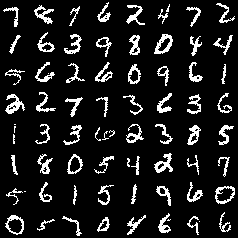

In [6]:
xs, = mnist_binary_loader |> first;
tensor2imgs(xs[:,:,:, 1:64]; nrows = 8, flip = false)

In [7]:
struct ConvNADEInputWrapper 
        with_mask::Bool
end
Flux.@layer ConvNADEInputWrapper # Registers the layer with Flux's backend

# Expects a tuple or pair containing (x, mask)
function (m::ConvNADEInputWrapper)((x, mask))
    if m.with_mask
        return cat(x .* mask, mask, dims=3)
    else
        return x .* mask
    end
end

In [8]:
function create_con_net(with_mask, filter_sizes, filters, valid_full, act =relu)
	net = []
	input_size = with_mask ? 2 : 1
	for l in 1:length(filters)
		padding = valid_full[l] ? 0 : filter_sizes[l] - 1
		if l == 1
			push!(net, Conv((filter_sizes[l], filter_sizes[l]), input_size => filters[l], act, pad = padding))
	

		elseif l == length(filters)
			push!(net, Conv((filter_sizes[l], filter_sizes[l]), filters[l-1] => filters[l], pad = padding))
		else

			push!(net, Conv((filter_sizes[l], filter_sizes[l]), filters[l-1] => filters[l], act, pad = padding))
		end
	end
	
	return Chain(net...)			   
end

create_con_net (generic function with 2 methods)

In [17]:
begin
    struct ConvNADE{T<:Flux.Chain}
        d::Int
        with_mask::Bool
        net::T
    end

    Flux.@layer ConvNADE trainable = (net,)


    function ConvNADE(d::Int=28^2, with_mask::Bool=true; smaller_net=true)
        if smaller_net
            net = create_con_net(with_mask, [5, 7, 7, 5], [4, 8, 4, 1], [true, true, false, false])
        else
            net = create_con_net(with_mask, [8, 4, 6, 7, 7, 6, 4, 8], [64, 64, 64, 64, 64, 64, 64, 1], [true, true, true, true, false, false, false, false])
        end
        input_wrapper = ConvNADEInputWrapper(with_mask)
        net = Chain(input_wrapper, net...)
        return ConvNADE(d, with_mask, net)
    end

    (m::ConvNADE)((xs, masks)) = m.net((xs, masks))


    function fit!(model::ConvNADE, data_loader, optim=Adam(3e-4), max_epochs=50; verbose=true, learning_rate_decay=true, validation_data=nothing, patience=Inf, every_epoch=10)
        total_d = model.d
        batch_size = data_loader.batchsize
        with_mask = model.with_mask
        initial_lr = optim.eta ## initial learning rate
        if learning_rate_decay
            total_batches_per_epoch = length(data_loader)
            total_steps = max_epochs * total_batches_per_epoch
            warmup_steps = Int(ceil(0.1 * total_steps))   # e.g., 10% of your training loop
            decay_steps = total_steps - warmup_steps  # The remaining steps in your training loop
            # 2. Define the two phases
            ss = WarmupLinear(1e-6, Float64(initial_lr), warmup_steps, total_steps, CosAnneal(Float64(initial_lr), 1e-6, decay_steps))
            # 3. Combine them chronologically into a single schedule
            schedule = ParameterSchedulers.Stateful(ss)
        end
        opt = Flux.setup(optim, model)
        losses = []
        mask_buffer = zeros(Bool, total_d, batch_size)
        validation_check = false
        best_model = deepcopy(model |> cpu)
        if !isnothing(validation_data)
            # Trackers for early stopping
            validation_check = true
            best_val_loss = Inf
            # To save a checkpoint of the best model
            epochs_no_improve = 0
        end
        @showprogress for epoch in 1:max_epochs
            for (xs,) in data_loader
                batch_size_real = size(xs)[end] ## in case mismatch size at the end
                cs = Array{Int}(undef, 1, batch_size_real)
                for i in 1:batch_size_real
                    ## 1. Uniformly pick exactly how many pixels this sample will see (0 to total d - 1)
                    c = rand(0:(total_d-1))
                    cs[1, i] = c
                    ## 2. Fill the column sequentially with the perfect number of 1s and 0s
                    @views mask_buffer[1:c, i] .= true
                    @views mask_buffer[(c+1):end, i] .= false
                    ## 3. Shuffle this sample's column in-place. 
                    ## This randomizes the coordinate layout with 0 allocations.
                    @views shuffle!(mask_buffer[:, i])
                end
                mask_buffer_gpu = (mask_buffer[:, 1:batch_size_real]) |> device
                xs_gpu = (xs) |> device
                masks = vec2tensor(mask_buffer_gpu)

                li, gs = Flux.withgradient(model) do m
                    preds = m((xs_gpu, masks))
                    preds_vecs = tensor2vec(preds)
                    xs_vecs = tensor2vec(xs_gpu)
                    negative_masks = .!mask_buffer_gpu
                    logLiks = sum(Flux.logitbinarycrossentropy(preds_vecs, xs_vecs; agg=identity) .* negative_masks, dims=1)
                    num_of_pixels = sum(negative_masks, dims=1)
                    (logLiks ./ num_of_pixels) * total_d |> mean
                end

                Flux.update!(opt, model, gs[1])
                push!(losses, cpu(li))


                if learning_rate_decay
                    next_lr = ParameterSchedulers.next!(schedule)
                    Flux.adjust!(opt, next_lr)
                end
            end

            # --- VALIDATION PHASE (End of Epoch) ---
            if validation_check
                current_val_loss = -logpdf_val(model, validation_data |> device)


                # --- EARLY STOPPING LOGIC ---
                if current_val_loss < best_val_loss
                    # New best found! Reset patience tracker and save parameters
                    best_val_loss = current_val_loss
                    best_model = deepcopy(model |> cpu) # Save snapshot
                    epochs_no_improve = 0
                else
                    # No improvement, increment counter
                    epochs_no_improve += 1
                end

                # Check if patience has run out
                if epochs_no_improve >= patience
                    println("🛑 Early stopping triggered! No improvement for $patience epochs.")
                    println("🏆 Best Validation Loss achieved: $(round(best_val_loss, digits=5))")
                    break
                end
            end

            if verbose && (epoch % every_epoch) == 1
                @info "Epoch $(epoch); Loss = $(round(losses[end]; digits=4))"
            end
        end
        return losses, best_model
    end

    function logpdf(model::ConvNADE, xs; reduction=mean, ensemble_size=1, one_order=true)
        n = size(xs)[end]
        total_d = model.d
        logliks = zeros32(ensemble_size, n) |> device
        xs_vec = tensor2vec(xs)
        for e in 1:ensemble_size
            masks = fill(false, size(xs)...) |> device
            masks_vec = tensor2vec(masks)
            if one_order
                orders = repeat(shuffle(1:total_d)', n)'
            else
                orders = hcat([shuffle(1:total_d) for _ in 1:n]...)
            end
            ll = zeros(n) |> device
            for d in 1:total_d
                preds_vec = tensor2vec(model((xs, masks)))
                ll += - Flux.logitbinarycrossentropy(preds_vec[CartesianIndex.(orders[d, :], 1:n)], xs_vec[CartesianIndex.(orders[d, :], 1:n)]; agg=identity)
                masks_vec[CartesianIndex.(orders[d, :], 1:n)] .= true
                masks = vec2tensor(masks_vec)
            end
            logliks[e, :] = ll
        end
        (logsumexp(logliks, dims=1) .- log(Float32(ensemble_size))) |> reduction
    end



    function logpdf(model::ConvNADE, data_loader::Flux.DataLoader; reduction=mean, ensemble_size=1, one_order=true)
        logLiks = []
        for (xs,) in data_loader
            xs = xs |> device
            logL = logpdf(model, xs; reduction = identity, ensemble_size=ensemble_size, one_order=one_order)[:]
            append!(logLiks, logL)
        end
        return logLiks |> reduction
    end


    function logpdf_val(model::ConvNADE, xs; reduction=mean, device=device)
        n = size(xs)[end] ## batch size
        total_d = model.d
        orders = hcat([shuffle(1:total_d) for _ in 1:n]...)
        # ds = Int(ceil(total_d ./ 2)) * ones(Int, n)
        ds = rand(1:total_d, n)
        masks = (orders .< ds') |> device
        negative_masks = .!masks
        preds = model((xs, vec2tensor(masks)))
        logLiks = -sum(Flux.logitbinarycrossentropy(tensor2vec(preds), tensor2vec(xs); agg=identity) .* negative_masks, dims=1)
        num_of_pixels = sum(negative_masks, dims=1)
        ((logLiks ./ num_of_pixels) * total_d |> reduction)
    end


    function sample(model::ConvNADE, n=1; sample_data=true)
        model = model
        total_d = model.d
        xs_samples = zeros(Bool, total_d, n) |> device
        ps_samples = similar(xs_samples, Float32, total_d, n)
        masks = fill(false, size(xs_samples)...) |> device
        orders = hcat([shuffle(1:total_d) for _ in 1:n]...)
        for d = 1:total_d
            xs_tensor = vec2tensor(xs_samples)
            masks_tensor = vec2tensor(masks)
            ps_vec = tensor2vec(model((xs_tensor, masks_tensor)))
            ps = ps_vec[CartesianIndex.(orders[d, :], 1:n)] .|> sigmoid
            # x_pixels = (rand32(size(ps)...) |> device) .< ps
            x_pixels = rand_like(ps) .< ps
            xs_samples[CartesianIndex.(orders[d, :], 1:n)] = x_pixels
            ps_samples[CartesianIndex.(orders[d, :], 1:n)] = ps
            masks[CartesianIndex.(orders[d, :], 1:n)] .= true
        end

        if sample_data
            return vec2tensor(xs_samples)
        else
            return vec2tensor(ps_samples)
        end
    end
end

sample (generic function with 2 methods)

In [10]:
begin
	Random.seed!(123)

	conv_nade = ConvNADE(28^2, true; smaller_net = false) |> device

	losses_connet, best_model = fit!(conv_nade, mnist_binary_loader, Adam(3e-4),  200; verbose = true, learning_rate_decay = true, validation_data = nothing, patience = Inf)
end

┌ Info: Epoch 1; Loss = 539.0726
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X11sdnNjb2RlLXJlbW90ZQ==.jl:116
Progress:   5%|██                                       |  ETA: 0:40:54┌ Info: Epoch 11; Loss = 168.1531
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X11sdnNjb2RlLXJlbW90ZQ==.jl:116
Progress:  10%|████▏                                    |  ETA: 0:22:03┌ Info: Epoch 21; Loss = 119.9264
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X11sdnNjb2RlLXJlbW90ZQ==.jl:116
Progress:  15%|██████▏                                  |  ETA: 0:15:34┌ Info: Epoch 31; Loss = 106.1951
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X11sdnNjb2RlLXJlbW90ZQ==.jl:116
Progress:  20%|████████▎                                |  ETA: 0:12:12┌ Info: Epoch 41; Loss = 102.2193
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df

(Any[543.6106f0, 542.1536f0, 542.1054f0, 542.0984f0, 542.0923f0, 542.042f0, 542.026f0, 541.9604f0, 541.9635f0, 541.8973f0  …  88.715164f0, 91.49281f0, 89.14561f0, 91.3857f0, 89.767235f0, 89.00464f0, 90.43407f0, 90.26167f0, 90.714966f0, 88.34433f0], ConvNADE{Chain{Tuple{ConvNADEInputWrapper, Conv{2, 4, typeof(relu), Array{Float32, 4}, Vector{Float32}}, Conv{2, 4, typeof(relu), Array{Float32, 4}, Vector{Float32}}, Conv{2, 4, typeof(relu), Array{Float32, 4}, Vector{Float32}}, Conv{2, 4, typeof(relu), Array{Float32, 4}, Vector{Float32}}, Conv{2, 4, typeof(relu), Array{Float32, 4}, Vector{Float32}}, Conv{2, 4, typeof(relu), Array{Float32, 4}, Vector{Float32}}, Conv{2, 4, typeof(relu), Array{Float32, 4}, Vector{Float32}}, Conv{2, 4, typeof(identity), Array{Float32, 4}, Vector{Float32}}}}}(784, true, Chain(ConvNADEInputWrapper(true), Conv((8, 8), 2 => 64, relu), Conv((4, 4), 64 => 64, relu), Conv((6, 6), 64 => 64, relu), Conv((7, 7), 64 => 64, relu), Conv((7, 7), 64 => 64, relu, pad=6), Conv(

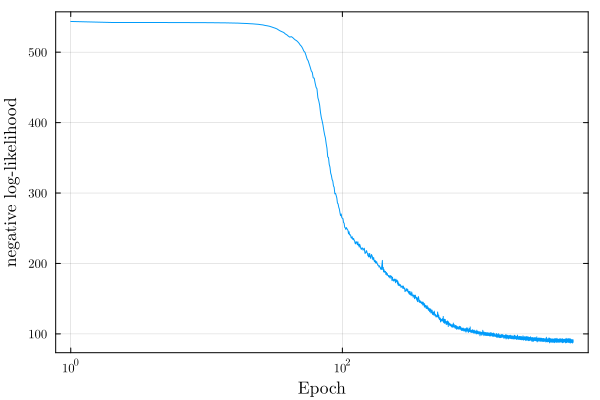

In [ ]:
begin

    plot_loss(losses_connet, length(mnist_binary_loader))
end

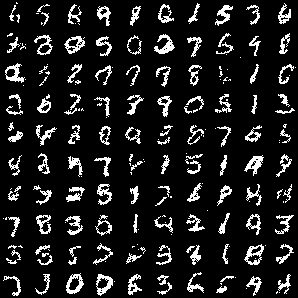

In [12]:
set_rand_seed(112233)
tensor2imgs(sample(conv_nade, 100); nrows = 10, flip = false)

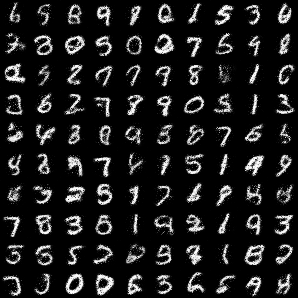

In [13]:
set_rand_seed(112233)
tensor2imgs(sample(conv_nade, 100; sample_data=false); nrows = 10, flip = false)

In [14]:
logpdf(conv_nade, mnist_binary_test[:, :, :, 1:1:end] |> device)

-90.02187f0

In [16]:
# logpdf(conv_nade, mnist_binary_test[:, :, :, 1:1000:end] |> device; ensemble_size=20, one_order=false)

-74.973694f0

In [19]:
## this is very slow for the whole test dataset; might take more than 20 mins!
mnist_binary_test_loader = Flux.DataLoader((mnist_binary_test[:, :, :, 1:10:end], ), batchsize = 2000)
logpdf(conv_nade, mnist_binary_test_loader; ensemble_size=20, one_order=false)

-86.86917f0